In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

Matplotlib is building the font cache; this may take a moment.


# Data Pre-processing

In [2]:
df = pd.read_csv("mdtraffic.csv",skipinitialspace=True)
df.head(5)

,ID,Severity,Start_Lat,Start_Lng,Distance(mi),Description,Side,City,County,State,...,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight,Street_Type
0,A-228553,1,39.152046,-76.645584,0.01,Accident on MD-100 Eastbound at Exits 13A 13A-...,R,Severn,Anne Arundel,MD,...,False,False,False,False,False,Day,Day,Day,Day,InterstateS
1,A-228554,2,39.152046,-76.645584,0.01,Lane blocked and right hand shoulder blocked d...,R,Severn,Anne Arundel,MD,...,False,False,False,False,False,Day,Day,Day,Day,InterstateS
2,A-228567,1,39.481083,-76.249626,0.01,Accident on MD-7 Philadelphia Rd at MD-543 Riv...,R,Belcamp,Harford,MD,...,False,False,False,True,False,Night,Day,Day,Day,local
3,A-228574,1,39.158756,-76.718475,0.01,Accident on MD-100 near Exits 10 10A 10B MD-71...,R,Hanover,Anne Arundel,MD,...,False,False,False,False,False,Night,Night,Day,Day,HighwayE
4,A-228580,1,39.636391,-77.710457,0.01,Accident on Cleveland Ave around Antietam St.,R,Hagerstown,Washington,MD,...,False,False,False,True,False,Night,Night,Day,Day,local


# Rove ID because it is irrelevant 

In [3]:
df.drop(["ID"], axis=1, inplace=True)
df.head(2)

,Severity,Start_Lat,Start_Lng,Distance(mi),Description,Side,City,County,State,Zipcode,...,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight,Street_Type
0,1,39.152046,-76.645584,0.01,Accident on MD-100 Eastbound at Exits 13A 13A-...,R,Severn,Anne Arundel,MD,21144,...,False,False,False,False,False,Day,Day,Day,Day,InterstateS
1,2,39.152046,-76.645584,0.01,Lane blocked and right hand shoulder blocked d...,R,Severn,Anne Arundel,MD,21144,...,False,False,False,False,False,Day,Day,Day,Day,InterstateS


# remove Twilights and only keep Sunrise_Sunset to determine time of day

In [4]:
df.drop(["Nautical_Twilight", "Astronomical_Twilight", "Civil_Twilight"], axis=1, inplace=True)
df.head(1)

,Severity,Start_Lat,Start_Lng,Distance(mi),Description,Side,City,County,State,Zipcode,...,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Street_Type
0,1,39.152046,-76.645584,0.01,Accident on MD-100 Eastbound at Exits 13A 13A-...,R,Severn,Anne Arundel,MD,21144,...,False,False,False,False,False,False,False,False,Day,InterstateS


# Drop rows with missing values

In [5]:
print(df.isna().sum())

columns_with_NA = [
    "Zipcode",
    "Temperature(F)",
    "Wind_Chill(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

df = df.dropna(subset=columns_with_NA)


Severity                 0
Start_Lat                0
Start_Lng                0
Distance(mi)             0
Description              0
Side                     0
City                     4
County                   0
State                    0
Zipcode                234
Country                  0
Temperature(F)        5948
Wind_Chill(F)        35083
Humidity(%)           6010
Pressure(in)          5561
Visibility(mi)       15111
Wind_Direction           0
Wind_Speed(mph)      22487
Precipitation(in)    37268
Weather_Condition        0
Amenity                  0
Bump                     0
Crossing                 0
Give_Way                 0
Junction                 0
No_Exit                  0
Railway                  0
Roundabout               0
Station                  0
Stop                     0
Traffic_Calming          0
Traffic_Signal           0
Turning_Loop             0
Sunrise_Sunset           4
Street_Type              0
dtype: int64


# Remove City, County and zipcode and keep state of MD

In [6]:
df.drop(["City", "County", "Zipcode"], axis=1, inplace=True)
df.head(1)

,Severity,Start_Lat,Start_Lng,Distance(mi),Description,Side,State,Country,Temperature(F),Wind_Chill(F),...,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Street_Type
179,2,39.235683,-76.709488,0.01,Two left lane closed due to accident on I-95 N...,R,MD,US,42.1,36.1,...,False,False,False,False,False,False,False,False,Day,InterstateN


# drop Description because of to many colums/ words

In [7]:
print(df["Description"])

df.drop(["Description"], axis=1, inplace=True)

179      Two left lane closed due to accident on I-95 N...
189      Left hand shoulder blocked due to serious acci...
190      Accident on I-97 Northbound at Exit 16 MD-648 ...
191      Accident on MD-32 Northbound after Linden Chur...
192      Left hand shoulder closed and through traffic ...
                               ...                        
69917    At MD-140/Baltimore Blvd - Accident. Lane bloc...
69918    At MD-140/Baltimore Blvd - Accident. Lane bloc...
69919    Closed between MD-66/Exit 35 and MD-65/Exit 29...
69920    At MD-7/Exit 34 - Multi-vehicle accident invol...
69921    At MD-187/Old Georgetown Rd/Exit 1 - Accident....
Name: Description, Length: 26785, dtype: object


# side left right to be numerical

In [8]:
df["Side"] = df.Side.map({"L":1,"R":0})

# Map some sort of order/direction for less columns

In [9]:
df["Sunrise_Sunset"] = df.Sunrise_Sunset.map({"Day":1,"Night":0})
print(df.shape)

(26785, 31)


# drop more irrelevant columns / not very specific to Severity

In [10]:
columns_to_drop = [
    "Start_Lat", "Start_Lng",
    "Amenity", "Bump", "Crossing", "Give_Way",
    "Junction", "No_Exit", "Railway", "Roundabout",
    "Station","Traffic_Calming", "Traffic_Signal",
    "Turning_Loop", "Wind_Direction",
]

df = df.drop(columns=columns_to_drop)
df

,Severity,Distance(mi),Side,State,Country,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Stop,Sunrise_Sunset,Street_Type
179,2,0.010,0,MD,US,42.1,36.1,67.0,30.09,10.0,10.4,0.00,Light Rain,False,1.0,InterstateN
189,1,4.650,0,MD,US,44.1,40.1,85.0,29.85,2.5,6.9,0.08,Light Rain,False,1.0,Highway
190,2,0.010,0,MD,US,42.1,35.2,100.0,29.83,2.0,12.7,0.08,Rain,False,0.0,Highway
191,1,0.010,0,MD,US,41.0,39.0,81.0,29.88,7.0,3.5,0.02,Overcast,False,0.0,Highway
192,1,0.010,0,MD,US,37.0,31.6,89.0,29.91,3.0,6.9,0.03,Light Rain,False,0.0,large_local
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69917,1,0.084,1,MD,US,75.0,75.0,89.0,29.10,3.0,0.0,0.44,Thunderstorms and Rain,False,1.0,local
69918,1,0.084,0,MD,US,75.0,75.0,89.0,29.10,3.0,0.0,0.44,Thunderstorms and Rain,False,1.0,local
69919,3,3.053,0,MD,US,75.0,75.0,84.0,29.17,10.0,5.0,0.00,Mostly Cloudy,False,0.0,InterstateW
69920,1,0.273,0,MD,US,72.0,72.0,100.0,29.98,10.0,3.0,0.00,Cloudy,False,1.0,InterstateN


# One hot encode the rest

In [11]:
df = pd.get_dummies(df,drop_first=True)
df = df.fillna(0).astype(int)
print(df.shape)
df

(26785, 48)


,Severity,Distance(mi),Side,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),...,Street_Type_HighwayN,Street_Type_HighwayS,Street_Type_HighwayW,Street_Type_InterstateE,Street_Type_InterstateN,Street_Type_InterstateS,Street_Type_InterstateW,Street_Type_Tunnel,Street_Type_large_local,Street_Type_local
179,2,0,0,42,36,67,30,10,10,0,...,0,0,0,0,1,0,0,0,0,0
189,1,4,0,44,40,85,29,2,6,0,...,0,0,0,0,0,0,0,0,0,0
190,2,0,0,42,35,100,29,2,12,0,...,0,0,0,0,0,0,0,0,0,0
191,1,0,0,41,39,81,29,7,3,0,...,0,0,0,0,0,0,0,0,0,0
192,1,0,0,37,31,89,29,3,6,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69917,1,0,1,75,75,89,29,3,0,0,...,0,0,0,0,0,0,0,0,0,1
69918,1,0,0,75,75,89,29,3,0,0,...,0,0,0,0,0,0,0,0,0,1
69919,3,3,0,75,75,84,29,10,5,0,...,0,0,0,0,0,0,1,0,0,0
69920,1,0,0,72,72,100,29,10,3,0,...,0,0,0,0,1,0,0,0,0,0


In [12]:
print(df.columns)

Index(['Severity', 'Distance(mi)', 'Side', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)',
       'Precipitation(in)', 'Stop', 'Sunrise_Sunset',
       'Weather_Condition_Cloudy', 'Weather_Condition_Drizzle',
       'Weather_Condition_Fair', 'Weather_Condition_Fog',
       'Weather_Condition_Haze', 'Weather_Condition_Heavy Rain',
       'Weather_Condition_Ice Pellets', 'Weather_Condition_Light Freezing Fog',
       'Weather_Condition_Light Freezing Rain', 'Weather_Condition_Light Rain',
       'Weather_Condition_Mostly Cloudy', 'Weather_Condition_Overcast',
       'Weather_Condition_Partly Cloudy', 'Weather_Condition_Rain',
       'Weather_Condition_Scattered Clouds', 'Weather_Condition_Snow',
       'Weather_Condition_Thunder', 'Weather_Condition_Thunderstorms and Rain',
       'Weather_Condition_Windy', 'Weather_Condition_Wintry Mix',
       'Weather_Condition_unknown', 'Street_Type_BeltwayN',
       'Street_Type_BeltwayS'

# If target is balanced

<Axes: >

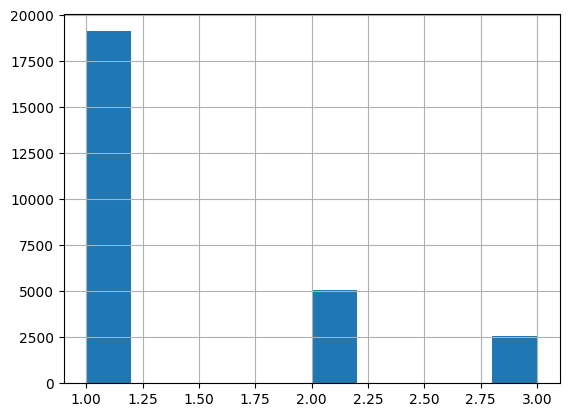

In [13]:
df["Severity"].hist()

# Data unbalanced so adjust weights in the pipeline
* f1 score instead of accuracy or balanced accuracy, set class_weight to balanced*
* upsample/downsample



# Get train/testing data

In [14]:
targets = df.Severity
data=df.drop(["Severity"],axis=1)
X_train, X_test, y_train, y_test = train_test_split(data,targets,stratify=targets,test_size=0.2)

# Combine X_train and y_train into a single DataFrame

In [15]:
train_data = pd.concat([X_train, y_train], axis=1)

# Combine X_test and y_test into a single DataFrame

In [16]:
test_data = pd.concat([X_test, y_test], axis=1)

In [17]:
train_data.to_csv('training_data.csv', index=False)

test_data.to_csv('testing_data.csv', index=False)